In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import community

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


In [6]:
df = pd.read_csv("Data/Connections.csv", skiprows=3)
display(df.head())

,First Name,Last Name,URL,Email Address,Company,Position,Connected On
0,Pasindu,Thambugala,https://www.linkedin.com/in/pasinduthambugala,NaN,MISL Holdings,Associate Software Engineer,17 Nov 2026
1,Rohtash,Bansal,https://www.linkedin.com/in/rohtash-bansal-b34...,NaN,Sprinklr,Senior Consultant,16 Nov 2026
2,Sandeepa,Nawarathne,https://www.linkedin.com/in/sandeepa-nawarathne,NaN,NaN,eBay Store Owner,13 Nov 2026
3,Dilshan,Molligoda,https://www.linkedin.com/in/dilshanmolligoda,NaN,NaN,NaN,12 Nov 2026
4,Nadeesha A.,Watawala,https://www.linkedin.com/in/nadeesha-w,NaN,Metaphase Global,Co-founder & Director/CEO,10 Nov 2026


In [24]:
EDGE_FILE = "Data/edges.csv"

import os
if os.path.exists(EDGE_FILE):
    edges = pd.read_csv(EDGE_FILE)
    assert {"source", "target"}.issubset(edges.columns), "edges.csv must have columns: source, target"
    display(edges.head())
    print("Edges shape:", edges.shape)
else:
    print(f"'{EDGE_FILE}' not found. Upload it, or use Option 2C.")

,source,target
0,0,1
1,1,0
2,0,2
3,2,0
4,0,3


Edges shape: (2220, 2)


In [25]:
# Build Graph
# Choose graph type
DIRECTED = False

# Basic validation
assert "edges" in globals(), "No 'edges' DataFrame found. Load/upload/generate edges first."
assert {"source", "target"}.issubset(edges.columns)

if DIRECTED:
    G = nx.from_pandas_edgelist(edges, "source", "target", create_using=nx.DiGraph())
else:
    G = nx.from_pandas_edgelist(edges, "source", "target", create_using=nx.Graph())

print("Graph Information")
print("------------------------")
print("Graph type:", type(G).__name__)
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is directed:", nx.is_directed(G))
print("Is weighted:", nx.is_weighted(G))
print("------------------------")

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Graph Information
------------------------
Graph type: Graph
Number of nodes: 698
Number of edges: 1521
Is directed: False
Is weighted: False
------------------------
Number of nodes: 698
Number of edges: 1521


In [26]:
# Compute Network Level Measures
def safe_diameter(graph):
    # Diameter only defined for connected graphs (or strongly connected for DiGraph)
    if graph.is_directed():
        if nx.is_strongly_connected(graph):
            return nx.diameter(graph)
        else:
            return None
    else:
        if nx.is_connected(graph):
            return nx.diameter(graph)
        else:
            return None

def average_shortest_path(graph):
    if graph.is_directed():
        if nx.is_strongly_connected(graph):
            return nx.average_shortest_path_length(graph)
        else:
            return None
    else:
        if nx.is_connected(graph):
            return nx.average_shortest_path_length(graph)
        else:
            return None

density = nx.density(G)
avg_degree = float(np.mean([d for _, d in G.degree()]))
diam = safe_diameter(G)
avg_path = average_shortest_path(G)

result = {
    "density": density,
    "average_degree": avg_degree,
    "diameter": diam,
    "average_shortest_path_length": avg_path,
    "is_directed": G.is_directed(),
}

if G.is_directed():
    result["reciprocity"] = nx.reciprocity(G)

pd.DataFrame([result])


,density,average_degree,diameter,average_shortest_path_length,is_directed
0,0.006253,4.358166,2,1.993747,False


In [27]:
# Compute node level measures 

# Centrality measures
deg_cent = nx.degree_centrality(G)
close_cent = nx.closeness_centrality(G)
between_cent = nx.betweenness_centrality(G, normalized=True)
cluster_coeff = nx.clustering(G.to_undirected())  # defined for undirected; works on underlying undirected

# Eigenvector centrality can fail to converge for some graphs; handle safely
try:
    eig_cent = nx.eigenvector_centrality(G.to_undirected(), max_iter=2000)
except Exception as e:
    print("Eigenvector centrality failed:", e)
    eig_cent = {n: np.nan for n in G.nodes()}

metrics_df = pd.DataFrame({
    "node": list(G.nodes()),
    "degree_centrality": [deg_cent[n] for n in G.nodes()],
    "closeness_centrality": [close_cent[n] for n in G.nodes()],
    "betweenness_centrality": [between_cent[n] for n in G.nodes()],
    "eigenvector_centrality": [eig_cent[n] for n in G.nodes()],
    "local_clustering": [cluster_coeff[n] for n in G.nodes()],
})

metrics_df.head()


,node,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality,local_clustering
0,0,1.000000,1.000000,0.996603,0.640820,0.003397
1,1,0.001435,0.500359,0.000000,0.022275,0.000000
2,2,0.001435,0.500359,0.000000,0.022275,0.000000
3,3,0.001435,0.500359,0.000000,0.022275,0.000000
4,4,0.001435,0.500359,0.000000,0.022275,0.000000


In [28]:
def topk(df, col, k=10):
    return df.sort_values(col, ascending=False).head(k)[["node", col]]

for col in ["degree_centrality", "closeness_centrality", "betweenness_centrality", "eigenvector_centrality", "local_clustering"]:
    print("\nTop nodes by", col)
    display(topk(metrics_df, col, k=10))



Top nodes by degree_centrality


,node,degree_centrality
0,0,1.000000
13,13,0.031564
697,697,0.031564
385,385,0.031564
369,369,0.031564
368,368,0.031564
341,341,0.031564
273,273,0.031564
209,209,0.031564
251,251,0.031564



Top nodes by closeness_centrality


,node,closeness_centrality
0,0,1.000000
13,13,0.508017
697,697,0.508017
385,385,0.508017
369,369,0.508017
368,368,0.508017
341,341,0.508017
273,273,0.508017
209,209,0.508017
251,251,0.508017



Top nodes by betweenness_centrality


,node,betweenness_centrality
0,0,0.996603
1,1,0.000000
2,2,0.000000
3,3,0.000000
4,4,0.000000
5,5,0.000000
6,6,0.000000
7,7,0.000000
8,8,0.000000
9,9,0.000000



Top nodes by eigenvector_centrality


,node,eigenvector_centrality
0,0,0.640820
13,13,0.082505
697,697,0.082505
385,385,0.082505
369,369,0.082505
368,368,0.082505
341,341,0.082505
273,273,0.082505
209,209,0.082505
251,251,0.082505



Top nodes by local_clustering


,node,local_clustering
697,697,1.0
695,695,1.0
694,694,1.0
693,693,1.0
675,675,1.0
672,672,1.0
671,671,1.0
670,670,1.0
667,667,1.0
666,666,1.0


Plotting subgraph with 300 nodes and 1123 edges


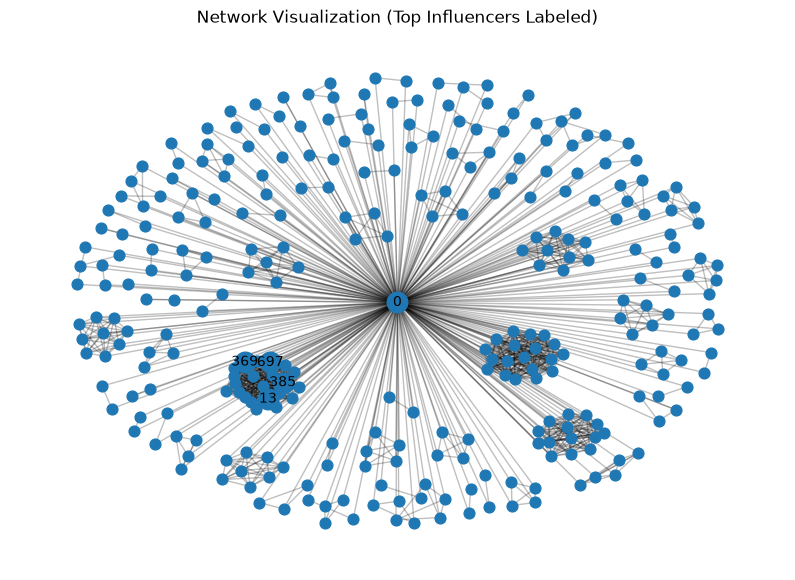

Top influencers (by eigenvector centrality): [0, 13, 697, 385, 369]


In [29]:
# Visualize the network

# Option: sample a subgraph for plotting if too large
MAX_NODES_TO_PLOT = 300

H = G
if G.number_of_nodes() > MAX_NODES_TO_PLOT:
    # sample nodes by degree (keep hubs)
    nodes_sorted = sorted(G.degree(), key=lambda x: x[1], reverse=True)
    keep_nodes = [n for n, _ in nodes_sorted[:MAX_NODES_TO_PLOT]]
    H = G.subgraph(keep_nodes).copy()
    print(f"Plotting subgraph with {H.number_of_nodes()} nodes and {H.number_of_edges()} edges")

# Identify top 5 influential nodes
top_influencers = topk(metrics_df, "eigenvector_centrality", k=5)["node"].tolist()

pos = nx.spring_layout(H, seed=RANDOM_SEED)

plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(H, pos, alpha=0.25)
nx.draw_networkx_nodes(H, pos, node_size=60)
nx.draw_networkx_nodes(H, pos, nodelist=[n for n in top_influencers if n in H.nodes()], node_size=220)
nx.draw_networkx_labels(H, pos, labels={n: str(n) for n in top_influencers if n in H.nodes()}, font_size=10)
plt.axis("off")
plt.title("Network Visualization (Top Influencers Labeled)")
plt.show()

print("Top influencers (by eigenvector centrality):", top_influencers)


In [30]:
# Community Detection
G_und = G.to_undirected()

communities = list(community.greedy_modularity_communities(G_und))
print("Number of communities detected:", len(communities))

# Community sizes
sizes = [len(c) for c in communities]
pd.DataFrame({"community_id": range(len(communities)), "size": sizes}).sort_values("size", ascending=False).head(10)


Number of communities detected: 37


,community_id,size
0,0,502
1,1,22
2,2,19
3,3,14
4,4,10
5,5,9
6,6,8
7,7,6
8,8,6
9,9,5


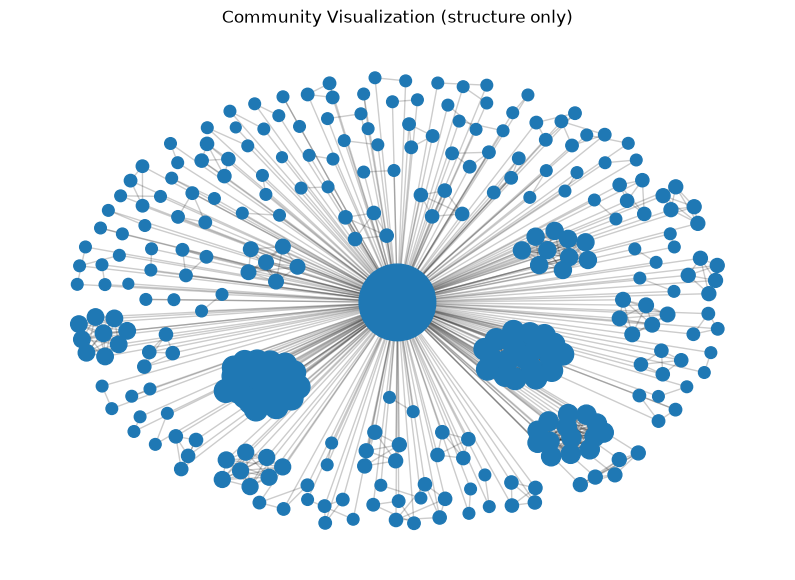

Note: In Colab we avoid custom colors to keep plotting simple.


In [31]:
# Visualize communities (on a plot-friendly subgraph)
MAX_NODES_TO_PLOT = 300
H = G_und
if H.number_of_nodes() > MAX_NODES_TO_PLOT:
    nodes_sorted = sorted(H.degree(), key=lambda x: x[1], reverse=True)
    keep_nodes = [n for n, _ in nodes_sorted[:MAX_NODES_TO_PLOT]]
    H = H.subgraph(keep_nodes).copy()

# Map node -> community id
node_to_comm = {}
for i, comm in enumerate(communities):
    for n in comm:
        node_to_comm[n] = i

# Positions
pos = nx.spring_layout(H, seed=RANDOM_SEED)

# Build node sizes by degree (simple emphasis)
node_sizes = [50 + 10*H.degree(n) for n in H.nodes()]

plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(H, pos, alpha=0.20)
nx.draw_networkx_nodes(
    H, pos,
    node_size=node_sizes
)
plt.axis("off")
plt.title("Community Visualization (structure only)")
plt.show()

print("Note: In Colab we avoid custom colors to keep plotting simple.")


In [32]:
# Choose a node to recommend connections for:
u = list(G_und.nodes())[0]  # change this to any node ID you want

def recommend_by_common_neighbors(G_und, u, k=10):
    # Candidates: nodes not already connected to u
    neighbors = set(G_und.neighbors(u))
    candidates = set(G_und.nodes()) - neighbors - {u}

    scores = []
    for v in candidates:
        # common neighbors count
        common = len(list(nx.common_neighbors(G_und, u, v)))
        if common > 0:
            scores.append((v, common))

    scores.sort(key=lambda x: x[1], reverse=True)
    return scores[:k]

recs = recommend_by_common_neighbors(G_und, u, k=10)
print("Recommendations for node:", u)
pd.DataFrame(recs, columns=["recommended_node", "mutual_neighbors"])


Recommendations for node: 0


,recommended_node,mutual_neighbors


In [33]:
# Robustness test
# Pick the most influential node
most_influential = topk(metrics_df, "eigenvector_centrality", k=1)["node"].iloc[0]
print("Most influential node:", most_influential)

Before = G_und.copy()
After = G_und.copy()
if most_influential in After:
    After.remove_node(most_influential)

def largest_component_size(Gx):
    if Gx.number_of_nodes() == 0:
        return 0
    comps = list(nx.connected_components(Gx))
    return max(len(c) for c in comps)

before_components = nx.number_connected_components(Before) if Before.number_of_nodes() else 0
after_components = nx.number_connected_components(After) if After.number_of_nodes() else 0

summary = pd.DataFrame([{
    "before_components": before_components,
    "after_components": after_components,
    "before_largest_component": largest_component_size(Before),
    "after_largest_component": largest_component_size(After),
    "nodes_before": Before.number_of_nodes(),
    "nodes_after": After.number_of_nodes(),
    "edges_before": Before.number_of_edges(),
    "edges_after": After.number_of_edges()
}])

summary


Most influential node: 0


,before_components,after_components,before_largest_component,after_largest_component,nodes_before,nodes_after,edges_before,edges_after
0,1,487,698,22,698,697,1521,824
